# Segment membrane and membrane cavities for more accurate measurement using ML

TODO:

- [x] select only the data containing the membrane and CL
- [x] set up ML and train on one sample
- [ ] apply classfier to test sample and segment all
    - [ ] align samples to not confuse location feature
    - [ ] refine classifier 
    - [ ] save all training sets to potetnially create one unified classifier

In [1]:
# modules
import os
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import dask
import dask.array
from scipy import ndimage
from skimage import filters, feature, io
from skimage.morphology import disk,ball
import sys
from itertools import combinations_with_replacement
import pickle
import imageio
import json
from dask.distributed import Client, LocalCluster
import socket
import subprocess
import gc

# import joblib
# 4 year old tutorial https://www.youtube.com/watch?v=5Zf6DQaf7jk&t=88s does this instead of importing joblib: 
# import dask_ml.joblib
# from sklearn.externals import joblib


from dask import config as cfg
cfg.set({'distributed.scheduler.worker-ttl': None, # Workaround so that dask does not kill workers while they are busy fetching data: https://dask.discourse.group/t/dask-workers-killed-because-of-heartbeat-fail/856, maybe this helps: https://www.youtube.com/watch?v=vF2VItVU5zg?
        'distributed.scheduler.transition-log-length': 100, #potential workaround for ballooning scheduler memory https://baumgartner.io/posts/how-to-reduce-memory-usage-of-dask-scheduler/
         'distributed.scheduler.events-log-length': 100
        })

# get the ML functions, TODO: make a library once it works/is in a stable state
pytrainpath = '/mpc/homes/fische_r/lib/pytrainseg'
cwd = os.getcwd()
os.chdir(pytrainpath)
from filter_functions import image_filter
import training_functions as tfs
from training_functions import train_segmentation
from segmentation import segmentation
pytrain_git_sha = subprocess.check_output(['git', 'rev-parse', '--short', 'HEAD']).decode().strip()
os.chdir(cwd)

#paths
host = socket.gethostname()
if host == 'mpc2959.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = '/mnt/SSD/fische_r/COELY'
    temppath = '/mnt/SSD/fische_r/tmp'
    temppath_2 = '/mpc/homes/fische_r/NAS/tmp'
    training_path = '/mpc/homes/fische_r/NAS/DASCOELY/processing/04_membrane_ML/'
    memlim = '700GB'
elif host == 'mpc2053.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = os.path.join(toppath, 'processing')
    temppath = '/mnt/SSD_2TB_nvme0n1/Robert/tmp/'
    temppath_2 = '/mpc/homes/fische_r/NAS/tmp'
    training_path = '/mpc/homes/fische_r/NAS/DASCOELY/processing/04_membrane_ML/'
    memlim = '360GB'
else:
    print('host '+host+' currently not supported')
    
path_02_4D = os.path.join(toppathSSD, '02_registered_3p1D') #h5 with registered data

# fetch githash
cwd = os.getcwd()
os.chdir(gitpath)
git_sha = subprocess.check_output(['git', 'rev-parse', '--short', 'HEAD']).decode().strip()
githash = subprocess.check_output(['git', 'rev-parse', 'HEAD']).decode().strip()
os.chdir(cwd)

### functionalities for interactive training

In [2]:
from ipywidgets import Image
from ipywidgets import ColorPicker, IntSlider, link, AppLayout, HBox
from ipycanvas import  hold_canvas,  MultiCanvas #RoughCanvas,Canvas,

def on_mouse_down(x, y):
    global drawing
    global position
    global shape
    drawing = True
    position = (x, y)
    shape = [position]

def on_mouse_move(x, y):
    global drawing
    global position
    global shape
    if not drawing:
        return
    with hold_canvas():
        canvas.stroke_line(position[0], position[1], x, y)
        position = (x, y)
    shape.append(position)

def on_mouse_up(x, y):
    global drawing
    global positiondu
    global shape
    drawing = False
    with hold_canvas():
        canvas.stroke_line(position[0], position[1], x, y)
        canvas.fill_polygon(shape)
    shape = []
    
def display_feature(i, TS):
    print('selected '+TS.feature_names[i])
    im = TS.current_feat_stack[:,:,i]
    im8 = im-im.min()
    im8 = im8/im8.max()*255
    return im8

### fire up dask

In [3]:
tempfolder = temppath  #a big SSD is a major adavantage to allow spill to disk and still be efficient. large dataset might crash with too small SSD or be slow with normal HDD
# tempfolder = temppath_2
dask.config.config['temporary-directory'] = tempfolder
# dask.config.config['distributed']['worker']['memory']['recent-to-old-time'] = '200000s'

# here you have the option to use a virtual cluster or even slurm on ra (not attempted yet)
cluster = LocalCluster(dashboard_address=':35000', memory_limit = memlim, n_workers=1) #settings optimised for mpc2959, play around if needed, if you know nothing else is using RAM then you can almost go to the limit
# maybe less workers with more threads makes better use of shared memory 

# scheduler_port = 'tcp://129.129.188.222:8786' #<-- if scheduler on mpc2959; scheduler on mpc2053 -> 'tcp://129.129.188.248:8786'
# cluster = scheduler_port

client = Client(cluster)
client.amm.start()
print('Dashboard at '+client.dashboard_link)

Dashboard at http://127.0.0.1:35000/status


## Test ROI selection

In [4]:
# sample = '8x'

In [5]:
# # file = '01_'+sample+'_rotated_3p1D.nc'
# file = '02_'+sample+'_registered_3p1D.nc'
# imagepath = os.path.join(path_02_4D, file)
# data = xr.open_dataset(imagepath)
# images = [im for im in data.keys() if im[3:7] == 'imag']
# images.sort()

In [6]:
# im300 = data[images[4]][:,:,300].data

In [7]:
# plt.imshow(im300[:,260:-260])

In [8]:
# data.close()

In [9]:
## [:, 250:-250, 50:-50] appears to be a good ROI for all samples

In [10]:
# crop = 260
# samplesall = ['1', '3II', '3III', '4', '4II', '5II', '5', '6', '7x', '8x']
# for sample in samplesall:
#     file = '02_'+sample+'_registered_3p1D.nc'
#     imagepath = os.path.join(path_02_4D, file)
#     data = xr.open_dataset(imagepath)
#     images = [im for im in data.keys() if im[3:7] == 'imag']
#     images.sort()
#     im300 = data[images[4]][:,:,300].data
#     im0 = data[images[4]][:,:,50].data
#     imfin = data[images[4]][:,:,-50].data
#     data.close()
#     fig, axs = plt.subplots(1,3)
#     axs[0].imshow(im300[:,crop:-crop])
#     axs[1].imshow(im0[:,crop:-crop])
#     axs[2].imshow(imfin[:,crop:-crop])
#     plt.title(sample +' '+ images[4])
    

## Data preparation

### create dask array

In [11]:
sample = '5'
file = '02_'+sample+'_registered_3p1D.nc'
imagepath = os.path.join(path_02_4D, file)
data = xr.open_dataset(imagepath)
images = [im for im in data.keys() if im[3:7] == 'imag']
images.sort()

In [12]:
t_utc = data['t_utc'].data
time = data['time'].data

In [13]:
# with obtained cropping data

# 3II
# a = 0
# b = -1
# c = 250
# d = -250
# e = 50
# f = -50

# 5
a = 10
b = -20
c = 280
d = -270
e = 50
f = -300

shp = data[images[4]][a:b, c:d, e:f].shape
# shp = data[images[4]][:, c:d, e:f].shape
shp = shp + (len(images),)

In [14]:
test_im1 = data[images[2]][a:b, c:d, e:f].data
test_im2 = data[images[-5]][a:b, c:d, e:f].data

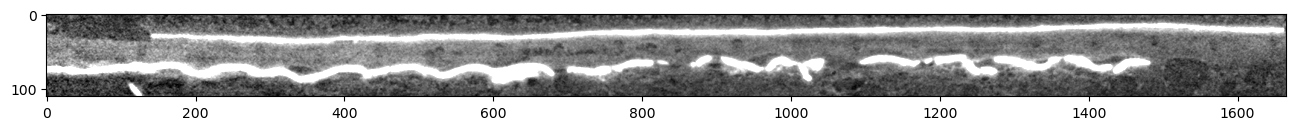

In [15]:
plt.figure(figsize=(16,9))
plt.imshow(test_im2[200,:, :], vmin =10000, vmax=15000, cmap='gray')

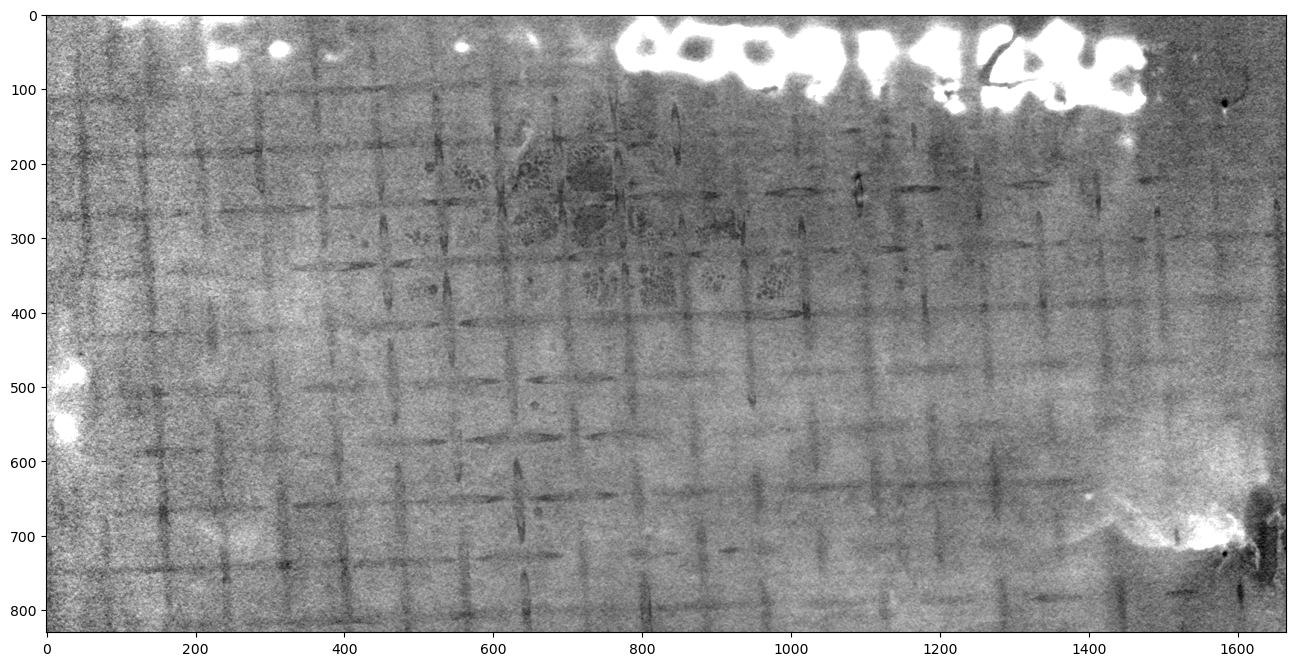

In [16]:
plt.figure(figsize=(16,9))
plt.imshow(test_im2[:,50, :], vmin =10000, vmax=15000, cmap='gray')

In [17]:
im = np.zeros(shp, dtype = np.uint16)

In [18]:
im.shape

(830, 110, 1666, 88)

In [19]:
# with obtained cropping data
for i in range(shp[-1]):
    if i%10 == 0:
        print(i)
    im[...,i] = data[images[i]][a:b, c:d, e:f].data
    # im[...,i] = data[images[i]][:, c:d, e:f].data

0
10
20
30
40
50
60
70
80


In [20]:
chunk_space = 36
da = dask.array.from_array(im, chunks = (chunk_space,chunk_space,chunk_space,len(images)))

In [21]:
del im
gc.collect() 

15

In [22]:
da

dask.array<array, shape=(830, 110, 1666, 88), dtype=uint16, chunksize=(36, 36, 36, 88), chunktype=numpy.ndarray>

In [23]:
data.close()

### get data into image filter class

In [24]:
# TODO: include this routine into pytrainseg

IF = image_filter() #default feauture settings sigmas = [0,2, 4],
# IF.loc_features =  True
IF.data = da
shp = da.shape
coords = {'x': np.arange(shp[0]), 'y': np.arange(shp[1]), 'z': np.arange(shp[2]), 'time': np.arange(shp[3])}
IF.original_dataset = xr.Dataset({'tomo': (['x','y','z','time'], da)},
                                 coords = coords
                                )

### prepare features

In [25]:
IF.prepare()

In [26]:
# IF.feature_names

In [27]:
IF.stack_features()

In [28]:
IF.compute_time_independent_features()

In [29]:
IF.feature_stack

dask.array<stack, shape=(830, 110, 1666, 88, 105), dtype=float64, chunksize=(36, 36, 36, 88, 1), chunktype=numpy.ndarray>

In [30]:
IF.make_xarray_nc()

## Training

### set up objects

In [31]:
training_path_sample = os.path.join(training_path, sample)
if not os.path.exists(training_path_sample):
    os.mkdir(training_path_sample)

In [32]:
TS = train_segmentation(training_path=training_path_sample)

In [33]:
TS.import_lazy_feature_data(IF.result, IF.original_dataset)

In [34]:
IF.combined_feature_names = list(IF.feature_names) + list(IF.feature_names_time_independent)

In [35]:
TS.combined_feature_names = IF.combined_feature_names

### interactive training

#### check for existing training sets

In [ ]:
training_path = '/mpc/homes/fische_r/NAS/DASCOELY/processing/04_membrane_ML/'

In [ ]:
os.listdir(os.path.join(training_path_sample, 'label_images'))

In [ ]:
git_sha

#### re-train with existing label sets. careful! clears the training dictionary (training_dict)

In [ ]:
TS.train()

#### import training dict of other samples 
(replace sample name and repeat for multiple samples), if necessary check features for overlap

In [ ]:
oldsample = '3II'
oldgitsha = '2d0f549'
training_dict_old = pickle.load(open(os.path.join(training_path, oldsample,  oldgitsha+'_training_dict.p'),'rb'))
# oldfeatures = pickle.load(open(os.path.join(training_path, oldsample,  oldgitsha+'_feature_names.p'),'rb'))
    
    # pickle.dump(TS.training_dict, open(os.path.join(TS.training_path, pytrain_git_sha+'_training_dict.p'),'wb'))
# pickle.dump(TS.feature_names, open(os.path.join(TS.training_path, pytrain_git_sha+'_feature_names.p'),'wb'))

for key in training_dict_old.keys():
    TS.training_dict[oldsample+key] = training_dict_old[key]

Process Dask Worker process (from Nanny):
2023-05-24 09:11:54,379 - distributed.nanny - ERROR - Worker process died unexpectedly
Traceback (most recent call last):
  File "/mpc/homes/fische_r/miniconda3/lib/python3.10/site-packages/distributed/nanny.py", line 988, in _run
    asyncio.run(run())
  File "/mpc/homes/fische_r/miniconda3/lib/python3.10/asyncio/runners.py", line 44, in run
    return loop.run_until_complete(main)
  File "/mpc/homes/fische_r/miniconda3/lib/python3.10/asyncio/base_events.py", line 636, in run_until_complete
    self.run_forever()
  File "/mpc/homes/fische_r/miniconda3/lib/python3.10/asyncio/base_events.py", line 603, in run_forever
    self._run_once()
  File "/mpc/homes/fische_r/miniconda3/lib/python3.10/asyncio/base_events.py", line 1868, in _run_once
    event_list = self._selector.select(timeout)
  File "/mpc/homes/fische_r/miniconda3/lib/python3.10/selectors.py", line 469, in select
    fd_event_list = self._selector.poll(timeout, max_ev)
KeyboardInterrup

In [40]:
oldsample = '5'
oldgitsha = '2d0f549'
training_dict_old = pickle.load(open(os.path.join(training_path, oldsample,  oldgitsha+'_training_dict.p'),'rb'))
# oldfeatures = pickle.load(open(os.path.join(training_path, oldsample,  oldgitsha+'_feature_names.p'),'rb'))
    
    # pickle.dump(TS.training_dict, open(os.path.join(TS.training_path, pytrain_git_sha+'_training_dict.p'),'wb'))
# pickle.dump(TS.feature_names, open(os.path.join(TS.training_path, pytrain_git_sha+'_feature_names.p'),'wb'))

for key in training_dict_old.keys():
    TS.training_dict[oldsample+key] = training_dict_old[key]

2023-05-16 15:19:49,880 - distributed.utils_perf - WARNING - full garbage collections took 19% CPU time recently (threshold: 10%)


#### suggest a new training coordinate

In [42]:
TS.suggest_training_set()

You could try  y = 27  and  time = 55
However, please sort it like the original xyztimetime_0feature


2023-05-16 15:20:09,912 - distributed.utils_perf - WARNING - full garbage collections took 19% CPU time recently (threshold: 10%)


In [63]:
c1 = 'x'
p1 = 430
c2 = 'time'
p2 = 37

In [64]:
TS.load_training_set(c1, p1, c2, p2)
im8 = TS.current_im8

In [65]:
feat_data = TS.feat_data
[c1,p1,c2,p2] = TS.current_coordinates
newslice = True

if c1 == 'x' and c2 == 'time':
    feat_stack = feat_data['feature_stack'].sel(x = p1, time = p2).data
    feat_stack_t_idp = feat_data['feature_stack_time_independent'].sel(x = p1, time_0 = 0).data
elif c1 == 'x' and c2 == 'y':
    feat_stack = feat_data['feature_stack'].sel(x = p1, y = p2).data
    feat_stack_t_idp = feat_data['feature_stack_time_independent'].sel(x = p1, y = p2).data
elif c1 == 'x' and c2 == 'z':
    feat_stack = feat_data['feature_stack'].sel(x = p1, z = p2).data
    feat_stack_t_idp = feat_data['feature_stack_time_independent'].sel(x = p1, z = p2).data
elif c1 == 'y' and c2 == 'z':
    feat_stack = feat_data['feature_stack'].sel(y = p1, z = p2).data
    feat_stack_t_idp = feat_data['feature_stack_time_independent'].sel(y = p1, z = p2).data
elif c1 == 'y' and c2 == 'time':
    feat_stack = feat_data['feature_stack'].sel(y = p1, time = p2).data
    feat_stack_t_idp = feat_data['feature_stack_time_independent'].sel(y = p1, time_0 = 0).data
elif c1 == 'z' and c2 == 'time':
    feat_stack = feat_data['feature_stack'].sel(z = p1, time = p2).data
    feat_stack_t_idp = feat_data['feature_stack_time_independent'].sel(z = p1, time_0 = 0).data


TS.current_feat_stack = dask.array.concatenate([feat_stack, feat_stack_t_idp], axis = 2)

if type(TS.current_feat_stack) is not np.ndarray:
    TS.current_computed = False

#### canvas for labeling

In [68]:
alpha = 0.35
# zoom1 = (-500,-1)
# zoom2 = (600,1400)

# zoom1 = (0, -1)
# zoom2 = (0, -1)

# im8 = TS.current_im8
#trick: use gaussian_time_4_0 to label static phases ()
# im8 = display_feature(-2, TS)
# im8 = display_feature(-20, TS)
# print(IF.combined_feature_names[-20])
print('original shape: ',im8.shape)
im8_display = im8.copy()#[zoom1[0]:zoom1[1], zoom2[0]:zoom2[1]]
# print('diyplay shape : ',im8_display.shape,' at: ', (zoom1[0], zoom2[0]))

resultim = TS.current_result.copy()

resultim_display = resultim#[zoom1[0]:zoom1[1], zoom2[0]:zoom2[1]]


width = im8_display.shape[1]
height = im8_display.shape[0]
Mcanvas = MultiCanvas(4, width=width, height=height)
background = Mcanvas[0]
resultdisplay = Mcanvas[2]
truthdisplay = Mcanvas[1]
canvas = Mcanvas[3]
canvas.sync_image_data = True
drawing = False
position = None
shape = []
image_data = np.stack((im8_display, im8_display, im8_display), axis=2)
background.put_image_data(image_data, 0, 0)
slidealpha = IntSlider(description="Result overlay", value=0.15)
resultdisplay.global_alpha = alpha #slidealpha.value
if np.any(resultim>0):
    result_data = np.stack((255*(resultim_display==0), 255*(resultim_display==1), 255*(resultim_display==2)), axis=2)
else:
    result_data = np.stack((0*resultim, 0*resultim, 0*resultim), axis=2)
resultdisplay.put_image_data(result_data, 0, 0)
canvas.on_mouse_down(on_mouse_down)
canvas.on_mouse_move(on_mouse_move)
canvas.on_mouse_up(on_mouse_up)
picker = ColorPicker(description="Color:", value="#ff0000") #red
# picker = ColorPicker(description="Color:", value="#0000ff") #blue
# picker = ColorPicker(description="Color:", value="#00ff00") #green

link((picker, "value"), (canvas, "stroke_style"))
link((picker, "value"), (canvas, "fill_style"))
link((slidealpha, "value"), (resultdisplay, "global_alpha"))

HBox((Mcanvas,picker))
# HBox((Mcanvas,)) #picker 

original shape:  (110, 1666)


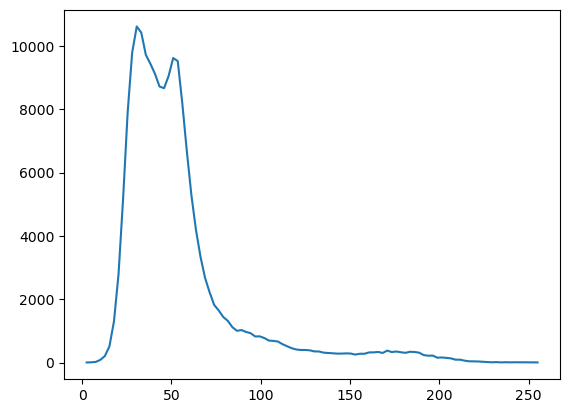

In [67]:
tfs.plot_im_histogram(im8)
# im8 = tfs.adjust_image_contrast(TS.current_im8, 0, 120)

#### inspect labels and training progress

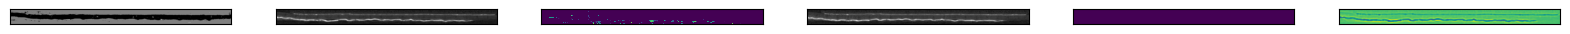

In [58]:
fig, axes = plt.subplots(1,6, figsize=(20,10))
axes[0].imshow(TS.current_result, 'gray')
axes[1].imshow(TS.current_im8, 'gray')

# TS.current_diff_im = TS.current_im-TS.current_first_im
# TS.current_diff_im = TS.current_diff_im/TS.current_diff_im.max()*255
axes[2].imshow(-TS.current_diff_im,vmin=6e4)
# axes[3].imshow(m8old, 'gray')
axes[3].imshow(TS.current_first_im, 'gray')
axes[4].imshow(TS.current_truth)
if TS.current_computed:
    axes[5].imshow(TS.current_feat_stack[:,:,-10])
else:
    axes[5].imshow(TS.current_result, 'gray')

for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])

In [59]:
# for i in range(TS.current_feat_stack.shape[2]):
#     plt.figure()
#     plt.imshow(TS.current_feat_stack[:,:,i])
#     plt.title(TS.combined_feature_names[i])

#### update training set if labels are ok

In [60]:
label_set = canvas.get_image_data()

# TS.current_truth[zoom1[0]:zoom1[1], zoom2[0]:zoom2[1]][label_set[:,:,0]>0] = 1
# TS.current_truth[zoom1[0]:zoom1[1], zoom2[0]:zoom2[1]][label_set[:,:,1]>0] = 2
# TS.current_truth[zoom1[0]:zoom1[1], zoom2[0]:zoom2[1]][label_set[:,:,2]>0] = 4

TS.current_truth[label_set[:,:,0]>0] = 1
TS.current_truth[label_set[:,:,1]>0] = 2
TS.current_truth[label_set[:,:,2]>0] = 4

imageio.imsave(TS.current_truthpath, TS.current_truth)

#### train!

In [ ]:
# TODO: see, if training gets slow for many label sets, currently stored in training_dict and read as loop. or if it is just the larger amount of data
TS.train_slice()

training and classifying


2023-05-16 17:23:31,615 - distributed.utils_perf - WARNING - full garbage collections took 13% CPU time recently (threshold: 10%)


In [109]:
# # load exisiting classifier and segment one slice
# clf = pickle.load(open(os.path.join(training_path, 'classifier.p'), 'rb'))
# feat = TS.current_feat_stack.compute()
# shp = feat[...,0].shape
# num_feat = feat.shape[-1]
# feat = feat.reshape(-1,num_feat)
# seg = clf.predict(feat)
# seg = seg.reshape(shp).astype(np.uint8)
# plt.figure(figsize=(16,9))
# plt.imshow(seg, cmap='gray_r')

#### go back until happy

#### check on training progress by plausible feature importance

Text(0, 0.5, 'importance')

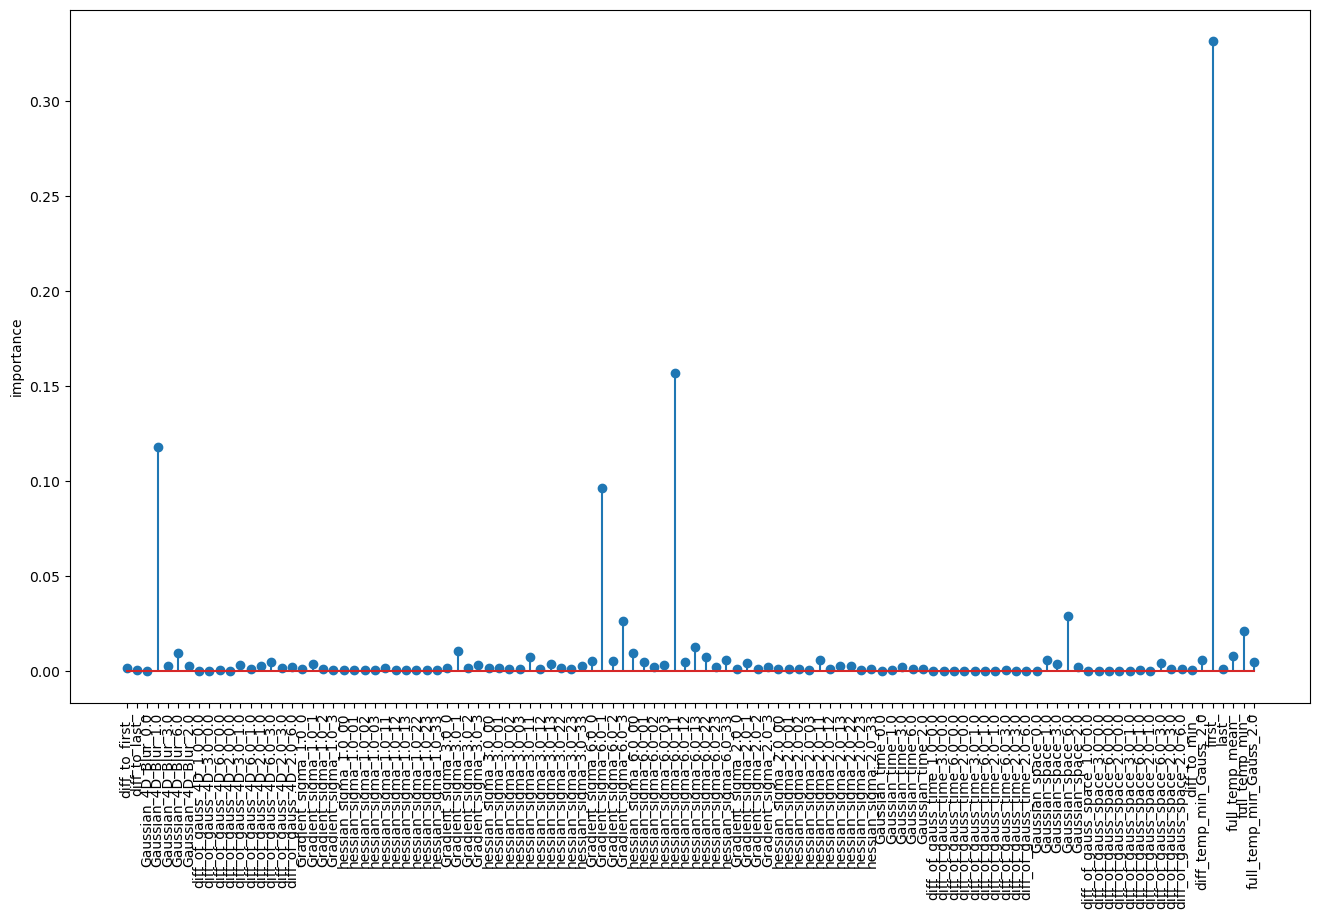

In [58]:
plt.figure(figsize=(16,9))
plt.stem(TS.combined_feature_names, TS.clf.feature_importances_,'x')
plt.xticks(rotation=90)
plt.ylabel('importance') 
# plt.xticks(rotation = 60)

### when done, maybe save the classifier and optional the training dict (avoids recalculating the training sets, but might be large)

In [69]:
TS.pickle_classifier()
pickle.dump(TS.training_dict, open(os.path.join(training_path_sample, git_sha+'_training_dict.p'),'wb'))
pickle.dump(TS.combined_feature_names, open(os.path.join(training_path_sample, git_sha+'_feature_names.p'),'wb'))


In [63]:
training_path

'/mpc/homes/fische_r/NAS/DASCOELY/processing/04_membrane_ML/'

In [61]:
# TS.training_dict

## Segmentation of full data set

remember that you removed features to train the clf

In [36]:
from segmentation import segmentation

In [37]:
classifier_path=os.path.join(training_path, 'classifier.p')
SM = segmentation(training_path = training_path, classifier_path=classifier_path)

In [38]:
# SM.import_lazy_feature_data(IF.result)
# SM.import_classifier(TS.clf)
SM.clf = pickle.load(open(os.path.join(training_path_sample, 'classifier.p'), 'rb'))

In [39]:
clf = SM.clf
clf.n_jobs = 64

if host == 'mpc2053.psi.ch':
    clf.n_jobs = 20

In [40]:
#TODO create result as a stream for every feature set of chunks, i.e stack of 67 feature chunks
# clf = TS.clf
# clf.n_jobs = 32

In [41]:
# loc_feats = [-4, -5, -6]
# ids = np.ones(72, dtype=bool)
# for f in loc_feats:
#     ids[f] = False

In [42]:
# ids

### merge time-independent features

In [43]:
test = dask.array.stack([TS.feat_data['feature_stack_time_independent'][:,:,:,0,:]]*da.shape[-1], axis=-2)

In [44]:
test

dask.array<stack, shape=(830, 110, 1666, 88, 5), dtype=float64, chunksize=(36, 36, 36, 1, 1), chunktype=numpy.ndarray>

In [45]:
feat = dask.array.concatenate([TS.feat_data['feature_stack'], test], axis=-1)

2023-06-05 08:46:45,597 - distributed.utils_perf - WARNING - full garbage collections took 12% CPU time recently (threshold: 10%)
2023-06-05 08:47:31,660 - distributed.utils_perf - WARNING - full garbage collections took 16% CPU time recently (threshold: 10%)
2023-06-05 08:48:21,191 - distributed.utils_perf - WARNING - full garbage collections took 15% CPU time recently (threshold: 10%)
2023-06-05 08:49:25,063 - distributed.utils_perf - WARNING - full garbage collections took 15% CPU time recently (threshold: 10%)
2023-06-05 08:50:42,152 - distributed.utils_perf - WARNING - full garbage collections took 15% CPU time recently (threshold: 10%)
2023-06-05 08:52:19,698 - distributed.utils_perf - WARNING - full garbage collections took 15% CPU time recently (threshold: 10%)
2023-06-05 08:54:20,903 - distributed.utils_perf - WARNING - full garbage collections took 15% CPU time recently (threshold: 10%)
2023-06-05 08:56:47,223 - distributed.utils_perf - WARNING - full garbage collections took

In [46]:
# feat = feat[...,ids]

In [47]:
feat

dask.array<concatenate, shape=(830, 110, 1666, 88, 110), dtype=float64, chunksize=(36, 36, 36, 1, 1), chunktype=numpy.ndarray>

### check aligment of chunks and select suitable "super-chunk" shape to split calculation in parts, example below

In [48]:
830*2.1

1743.0

In [49]:
350/50

7.0

In [50]:
i = 12
j = 11
# j = 3
dim1 = 72#better use multiple of chunk size !?
dim2 = int(2.1*dim1)
feat[i*dim1:(i+1)*dim1,:,j*dim2:(j+1)*dim2,:,:] #select all features and all time steps, but you are free in space; als large as possible and as small as necessary. limit is the available RAM to collect the dask result

dask.array<getitem, shape=(0, 110, 5, 88, 110), dtype=float64, chunksize=(0, 36, 5, 1, 1), chunktype=numpy.ndarray>

In [51]:
# segs = np.zeros(feat.shape[:4], dtype=np.uint8)
segs = pickle.load(open(os.path.join(training_path,'segs.p'), 'rb'))

2023-06-05 09:01:59,966 - distributed.utils_perf - WARNING - full garbage collections took 15% CPU time recently (threshold: 10%)


In [52]:
# import gc
client.run(gc.collect)
gc.collect()

2023-06-05 09:02:52,758 - distributed.utils_perf - WARNING - full garbage collections took 14% CPU time recently (threshold: 10%)


40

In [53]:
import ctypes
def trim_memory() -> int:
    libc = ctypes.CDLL("libc.so.6")
    return libc.malloc_trim(0)

In [ ]:
limit = 12
# TODO: Workaround: write intermediates to disk and restart dask client/scheduler/workers to get rid of unmanaged memory
# possible solution: do data handling on mpc2053 and calculations on mpc2959 -> leaves some RAM --> gc.collect() not necessary anymore
# appearantly starts to become critical after 12 iteratons
# from i=7, j=10 already done
# TODO write i and j to file to track progress even when closing jupyter
for i in range(11,limit):
    pickle.dump(segs, open(os.path.join(training_path,'segs_temp.p'), 'wb'))
    
    print(str(i+1)+'/'+str(limit))
    # plt.figure()
    # plt.imshow(segs[:,100,:, 50])
    # plt.savefig(os.path.join(training_path, sample+'_'+str(i)+'_progress.png'))
    # client.run(gc.collect)
    # client.run(trim_memory)
    start = 0
    if i == 11:
        start = 4
    for j in range(start,limit):
        gc.collect() 
        client.run(gc.collect)
        client.run(trim_memory)
        print(j)
        #with joblib.parallel_backend('dask'):
        part = feat[i*dim1:(i+1)*dim1,:,j*dim2:(j+1)*dim2,:,:] #.persist() #compute() may blow up the memory ?! https://stackoverflow.com/questions/73770527/dask-compute-uses-twice-the-expected-memory
        if 0 in part.shape:
            print('hit the edge (one dimension 0), ignore')
            continue
        part = part.compute()
        # try to release old unmanaged memory
        client.run(gc.collect)
        client.run(trim_memory)

        shp = part.shape
        num_feat = part.shape[-1]  
        part = part.reshape(-1,num_feat)

        psplit = int(part.shape[0]/2)

        print('create part 1')
        part1 = part[:psplit,:]
        print('create part 2')
        part2 = part[psplit:,:]
        print('segmenting 1')

        # with joblib.parallel_backend('dask'):
        seg1 = clf.predict(part1).astype(np.uint8)
        del part1
        print('segmenting 2')
        # with joblib.parallel_backend('dask'):
        seg2 = clf.predict(part2).astype(np.uint8)
        print('wrap results')
        del part2
        del part
        # gc.collect()

        seg = np.concatenate([seg1,seg2])
        print(seg.shape)
        del seg1
        del seg2

        seg = seg.reshape(shp[:4])  #this step needs a lot of RAM ?! appearantly not
    
    # not sure if this switch cases are necessary
        if i < limit-1 and j < limit-1:
            segs[i*dim1:(i+1)*dim1,:,j*dim2:(j+1)*dim2,:] = seg
        elif not i < limit-1 and j < limit-1:
            segs[i*dim1:,:,j*dim2:(j+1)*dim2,:] =  seg
        elif not j < limit-1 and i < limit-1:
            segs[i*dim1:(i+1)*dim1,:,j*dim2:,:] =  seg
        else:
            segs[i*dim1:,:,j*dim2:,:] = seg
            
        del seg

2023-06-05 09:03:00,032 - distributed.utils_perf - WARNING - full garbage collections took 10% CPU time recently (threshold: 10%)
2023-06-05 09:03:02,392 - distributed.utils_perf - WARNING - full garbage collections took 10% CPU time recently (threshold: 10%)
2023-06-05 09:03:04,246 - distributed.utils_perf - WARNING - full garbage collections took 10% CPU time recently (threshold: 10%)
2023-06-05 09:03:07,012 - distributed.utils_perf - WARNING - full garbage collections took 11% CPU time recently (threshold: 10%)
2023-06-05 09:03:09,816 - distributed.utils_perf - WARNING - full garbage collections took 11% CPU time recently (threshold: 10%)
2023-06-05 09:03:12,079 - distributed.utils_perf - WARNING - full garbage collections took 12% CPU time recently (threshold: 10%)
2023-06-05 09:03:15,133 - distributed.utils_perf - WARNING - full garbage collections took 13% CPU time recently (threshold: 10%)
2023-06-05 09:03:18,017 - distributed.utils_perf - WARNING - full garbage collections took

12/12


2023-06-05 09:03:25,373 - distributed.utils_perf - WARNING - full garbage collections took 14% CPU time recently (threshold: 10%)
2023-06-05 09:03:48,480 - distributed.utils_perf - WARNING - full garbage collections took 16% CPU time recently (threshold: 10%)
2023-06-05 09:03:49,301 - distributed.utils_perf - WARNING - full garbage collections took 15% CPU time recently (threshold: 10%)


4


2023-06-05 09:06:18,554 - distributed.utils_perf - WARNING - full garbage collections took 15% CPU time recently (threshold: 10%)
2023-06-05 09:06:40,716 - distributed.utils_perf - WARNING - full garbage collections took 16% CPU time recently (threshold: 10%)
2023-06-05 09:08:22,223 - distributed.utils_perf - WARNING - full garbage collections took 16% CPU time recently (threshold: 10%)
2023-06-05 09:09:22,912 - distributed.utils_perf - WARNING - full garbage collections took 15% CPU time recently (threshold: 10%)
2023-06-05 09:09:27,910 - distributed.utils_perf - WARNING - full garbage collections took 20% CPU time recently (threshold: 10%)
2023-06-05 09:09:58,324 - distributed.utils_perf - WARNING - full garbage collections took 19% CPU time recently (threshold: 10%)
2023-06-05 09:10:27,731 - distributed.utils_perf - WARNING - full garbage collections took 19% CPU time recently (threshold: 10%)
2023-06-05 09:10:45,365 - distributed.utils_perf - WARNING - full garbage collections took

create part 1
create part 2
segmenting 1
segmenting 2
wrap results
(55543840,)


... (11 outputs left out)

create part 1
create part 2
segmenting 1
segmenting 2
wrap results
(55543840,)


2023-06-05 12:56:54,179 - distributed.utils_perf - WARNING - full garbage collections took 15% CPU time recently (threshold: 10%)


8


2023-06-05 13:05:17,897 - distributed.utils_perf - WARNING - full garbage collections took 15% CPU time recently (threshold: 10%)
2023-06-05 13:08:46,660 - distributed.utils_perf - WARNING - full garbage collections took 16% CPU time recently (threshold: 10%)


### check progress and save

In [55]:
i

11

In [56]:
j

4

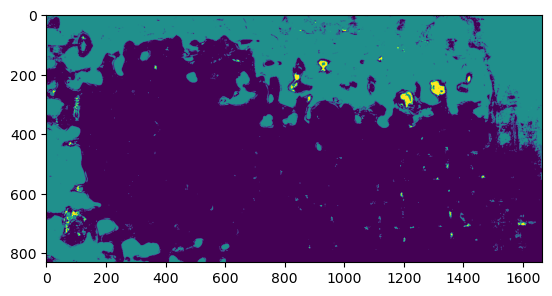

In [57]:
plt.imshow(segs[:,65,:, 30])

In [58]:
pickle.dump(segs, open(os.path.join(training_path,'segs.p'), 'wb'))

### save result to disk

In [59]:
# TODO: include metadata in segmented nc and

shp = segs.shape
segdata = xr.Dataset({'segmented': (['x','y','z','timestep'], segs),
                     't_utc': ('timestep', t_utc),
                     'time': ('timestep', time)},
                               coords = {'x': np.arange(shp[0]),
                               'y': np.arange(shp[1]),
                               'z': np.arange(shp[2]),
                               'timestep': np.arange(shp[3]),
                               'feature': TS.combined_feature_names}
                     )
segdata.attrs = data.attrs.copy()
segdata.attrs['05_ML_cropping'] = [a,b,c,d,e,f]
segdata.attrs['pytrain_git'] = pytrain_git_sha
segdata.attrs['05_coely_gitsha'] = git_sha

In [60]:
segpath = os.path.join(training_path_sample, sample+'membrane_segmentation.nc')

In [61]:
segdata.to_netcdf(segpath)